# Commercial Probability of Default (PD) Model

**Prairie Lantern Bank, N.A. | Commercial & CRE portfolio | Prepared by Matthew Dial**

This notebook builds a 12-month probability of default model for commercial borrowers, validates it out of time, converts it to a scorecard and the bank's 9-grade master scale, and uses it to estimate expected loss on the current book.

> **All data is synthetic.** Borrowers, financials, and defaults were simulated by `data/generate_data.py`. The goal is to show the workflow a credit risk analyst would follow, not to make claims about real default behavior.

**Workflow**
1. Build the modeling dataset with SQL
2. Explore default rates
3. Bin variables, calculate Weight of Evidence (WoE) and Information Value (IV)
4. Fit a logistic regression on WoE variables
5. Validate on an out-of-time sample (AUC, Gini, KS, calibration)
6. Build the points-based scorecard and map PDs to the master scale
7. Benchmark against the bank's judgmental grades
8. Score the current portfolio and calculate expected loss

In [1]:
import sqlite3, numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.metrics import roc_auc_score, roc_curve
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 140)
DB = "../data/prairie_lantern_loans.db"
FIG = "../figures/"
con = sqlite3.connect(DB)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.axisbelow": True})
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#898781"

## 1. Modeling dataset

One observation per borrower per fiscal year. Features come from that year's financial statements; the target is whether the borrower defaults (90+ days past due or nonaccrual) in the following 12 months.

| Sample | Fiscal years | Outcome window | Use |
|---|---|---|---|
| Development | FY2022, FY2023 | 2023, 2024 | Fit the model |
| Out-of-time (OOT) | FY2024 | 2025 | Validate on a later period the model never saw |
| Scoring | FY2025 | 2026 (partly observed) | Score the current book |

*Simplification: the outcome window starts at the statement date. In practice it would start when statements are received (about 120 days later).*

In [2]:
sql = '''
WITH f AS (
    SELECT f.*, b.sector, b.industry, b.guarantor, b.years_in_business,
           LAG(f.dscr) OVER (PARTITION BY f.borrower_id ORDER BY f.fiscal_year)    AS prior_dscr,
           LAG(f.revenue) OVER (PARTITION BY f.borrower_id ORDER BY f.fiscal_year) AS prior_revenue
    FROM financials f JOIN borrowers b ON b.borrower_id = f.borrower_id
)
SELECT f.*,
       EXISTS (SELECT 1 FROM defaults d
               WHERE d.borrower_id = f.borrower_id
                 AND d.default_date BETWEEN (f.fiscal_year + 1) || '-01-01' AND (f.fiscal_year + 1) || '-12-31') AS default_12m
FROM f
'''
df = pd.read_sql(sql, con)
df["dscr_change"] = np.log(df["dscr"] / df["prior_dscr"]).fillna(0)
df["revenue_growth"] = (df["revenue"] / df["prior_revenue"] - 1).fillna(0)
df["sample"] = np.select([df.fiscal_year <= 2023, df.fiscal_year == 2024], ["Development", "Out-of-time"], "Scoring")
summary = df.groupby("sample").agg(observations=("borrower_id", "size"), defaults=("default_12m", "sum"), default_rate=("default_12m", "mean"))
summary

,observations,defaults,default_rate
sample,,,
Development,2633,40,0.0152
Out-of-time,1460,31,0.0212
Scoring,1429,34,0.0238


Commercial portfolios are **low-default portfolios**: only a few dozen defaults in each sample. That shapes every choice below: coarse bins, few variables, and a preference for an interpretable model over a complex one.

## 2. Exploratory analysis

In [3]:
dev_oot = df[df["sample"] != "Scoring"]
by_ind = (dev_oot.groupby(["sector", "industry"]).agg(obs=("default_12m", "size"), defaults=("default_12m", "sum"), default_rate=("default_12m", "mean"))
          .sort_values("default_rate", ascending=False))
by_ind

obs  defaults  default_rate
sector industry                                           
CRE    CRE - Hospitality       128         8        0.0625
       CRE - Office            278        15        0.0540
C&I    Restaurants             139         6        0.0432
       Retail Trade            173         6        0.0347
CRE    CRE - Senior Housing    142         4        0.0282
C&I    Transportation          263         6        0.0228
       Construction            317         7        0.0221
       Energy Services         193         4        0.0207
CRE    CRE - Retail            230         4        0.0174
C&I    Agriculture             127         2        0.0157
       Professional Services   224         3        0.0134
CRE    CRE - Self Storage      181         2        0.0110
C&I    Wholesale Distribution  226         2        0.0088
CRE    CRE - Multifamily       510         2        0.0039
C&I    Manufacturing           354         0        0.0000
       Healthcare              289         0        0.0000
CRE    CRE - Industrial        319         0        0.0000

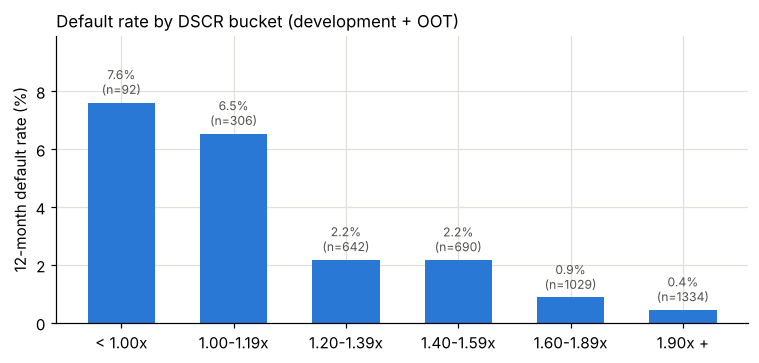

In [4]:
bins = [0, 1.0, 1.2, 1.4, 1.6, 1.9, 99]
labels = ["< 1.00x", "1.00-1.19x", "1.20-1.39x", "1.40-1.59x", "1.60-1.89x", "1.90x +"]
t = dev_oot.assign(bucket=pd.cut(dev_oot.dscr, bins, labels=labels, right=False)).groupby("bucket", observed=True)["default_12m"].agg(["size", "mean"])
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(t.index.astype(str), t["mean"] * 100, color=BLUE, width=0.6)
for i, (n, r) in enumerate(zip(t["size"], t["mean"])):
    ax.text(i, r * 100 + 0.3, f"{r*100:.1f}%\n(n={n})", ha="center", fontsize=8, color="#52514e")
ax.set_ylim(0, t["mean"].max() * 100 * 1.3); ax.set_ylabel("12-month default rate (%)"); ax.set_title("Default rate by DSCR bucket (development + OOT)", loc="left", fontsize=11)
plt.tight_layout(); plt.savefig(FIG + "default_rate_by_dscr.png"); plt.show()

Default rates fall steadily as debt service coverage rises, which is the relationship the model needs to capture.

## 3. Weight of Evidence and Information Value

Each variable is cut into a few bins. For each bin:

- **WoE** = ln(share of defaults in bin / share of non-defaults in bin). Positive WoE means riskier than average.
- **IV** = sum of (share of defaults - share of non-defaults) x WoE. Rule of thumb: under 0.02 is not useful, 0.02 to 0.1 weak, 0.1 to 0.3 medium, above 0.3 strong.

Sector-specific ratios (leverage and current ratio for C&I, LTV for CRE) are binned within their own sector, and borrowers they don't apply to get a neutral WoE of 0. Giving them their own "N/A" bin would let the variable act as a hidden sector flag. Industry uses a judgmental risk tier, the way an analyst would use an industry risk rating, because single industries have too few defaults to estimate reliably.

In [5]:
TIER = {"CRE - Office": "High", "CRE - Hospitality": "High", "Restaurants": "High", "Transportation": "High", "Energy Services": "High",
        "Construction": "High", "Retail Trade": "High", "CRE - Senior Housing": "High", "CRE - Retail": "Medium", "Agriculture": "Medium",
        "Wholesale Distribution": "Medium", "Manufacturing": "Medium", "CRE - Multifamily": "Low", "CRE - Industrial": "Low",
        "CRE - Self Storage": "Low", "Healthcare": "Low", "Professional Services": "Low"}
df["industry_tier"] = df["industry"].map(TIER)

# Bin edges were chosen on the development sample by starting with finer cuts and merging
# neighbors until default rates moved in one direction (monotonic WoE). Edges stay fixed for OOT and scoring.
EDGES = {
    "dscr":                  [-np.inf, 1.15, 1.30, 1.50, 1.85, np.inf],
    "dscr_change":           [-np.inf, -0.20, -0.08, np.inf],
    "funded_debt_to_ebitda": [-np.inf, 2.8, np.inf],
    "current_ratio":         [-np.inf, 1.5, np.inf],
    "ltv":                   [-np.inf, 0.55, 0.65, 0.75, np.inf],
    "years_in_business":     [-np.inf, 8, 15, 25, np.inf],
}
CATEG = ["industry_tier", "guarantor"]

def binned(frame, var):
    if var in CATEG:
        return frame[var].astype(str)
    b = pd.cut(frame[var], EDGES[var], right=False).astype(str)
    return b.where(frame[var].notna(), "N/A")

SECTOR_VARS = {"funded_debt_to_ebitda": "C&I", "current_ratio": "C&I", "ltv": "CRE"}

def woe_table(frame, var, target="default_12m", smooth=0.5):
    # Sector-specific ratios are binned only within their own sector. Borrowers they don't apply to get WoE = 0
    # (neutral); otherwise the "N/A" bin would just become a proxy for sector.
    if var in SECTOR_VARS: frame = frame[frame["sector"] == SECTOR_VARS[var]]
    g = frame.assign(bin=binned(frame, var)).groupby("bin")[target].agg(obs="size", bad="sum")
    g["good"] = g["obs"] - g["bad"]
    g["dist_bad"] = (g["bad"] + smooth) / (g["bad"].sum() + smooth * len(g))
    g["dist_good"] = (g["good"] + smooth) / (g["good"].sum() + smooth * len(g))
    g["bad_rate"] = g["bad"] / g["obs"]
    g["woe"] = np.log(g["dist_bad"] / g["dist_good"])
    g["iv"] = (g["dist_bad"] - g["dist_good"]) * g["woe"]
    return g

dev = df[df["sample"] == "Development"].copy()
VARS = list(EDGES) + CATEG
WOE = {v: woe_table(dev, v) for v in VARS}
iv = pd.Series({v: WOE[v]["iv"].sum() for v in VARS}, name="IV").sort_values(ascending=False).to_frame()
iv["strength"] = pd.cut(iv["IV"], [0, 0.02, 0.1, 0.3, 9], labels=["Not useful", "Weak", "Medium", "Strong"])
iv

,IV,strength
dscr,1.0987,Strong
ltv,0.8462,Strong
industry_tier,0.7718,Strong
dscr_change,0.4053,Strong
years_in_business,0.0135,Not useful
funded_debt_to_ebitda,0.0096,Not useful
current_ratio,0.0054,Not useful
guarantor,0.0023,Not useful


In [6]:
WOE["dscr"][["obs", "bad", "bad_rate", "woe", "iv"]]

,obs,bad,bad_rate,woe,iv
bin,,,,,
"[-inf, 1.15)",145,14,0.0966,1.9072,0.5541
"[1.15, 1.3)",212,6,0.0283,0.6535,0.0480
"[1.3, 1.5)",448,10,0.0223,0.3800,0.0297
"[1.5, 1.85)",867,6,0.0069,-0.7748,0.1387
"[1.85, inf)",961,4,0.0042,-1.2482,0.3283


### Variable selection

Keep variables with IV of at least 0.02 whose WoE moves in one direction across bins (for example, risk should fall as DSCR rises). Statistics alone don't decide: a variable with some IV but a pattern a credit officer couldn't explain is left out. Then check that the selected variables are not too correlated with each other.

In [7]:
def monotonic(var):
    if var in CATEG: return True                      # categories have no natural order
    w = WOE[var]["woe"].drop("N/A", errors="ignore")
    w = w.loc[sorted(w.index, key=lambda b: float(b.split(",")[0].strip("[")))]
    d = np.diff(w.values); return bool((d <= 0).all() or (d >= 0).all())
selected = []
for v in iv.index:
    if iv.loc[v, "IV"] < 0.02: print(f"Excluded {v}: IV below 0.02")
    elif not monotonic(v): print(f"Excluded {v}: WoE not monotonic across bins, hard to defend to a credit officer")
    else: selected.append(v)
def apply_woe(frame, vars_):
    out = pd.DataFrame(index=frame.index)
    for v in vars_:
        m = WOE[v]["woe"]; out["woe_" + v] = binned(frame, v).map(m).fillna(0.0)
    return out
X_dev = apply_woe(dev, selected)
print("Selected:", selected)
X_dev.corr().round(2)

Excluded years_in_business: IV below 0.02
Excluded funded_debt_to_ebitda: IV below 0.02
Excluded current_ratio: IV below 0.02
Excluded guarantor: IV below 0.02
Selected: ['dscr', 'ltv', 'industry_tier', 'dscr_change']


,woe_dscr,woe_ltv,woe_industry_tier,woe_dscr_change
woe_dscr,1.0000,0.0400,0.1500,0.3300
woe_ltv,0.0400,1.0000,0.1400,0.1900
woe_industry_tier,0.1500,0.1400,1.0000,0.0900
woe_dscr_change,0.3300,0.1900,0.0900,1.0000


## 4. Logistic regression

In [8]:
# Backward elimination: with WoE coding every coefficient should be positive.
# Drop wrong-sign variables first, then any variable with p-value above 0.20, one at a time, refitting each time.
while True:
    model = sm.Logit(dev["default_12m"], sm.add_constant(X_dev)).fit(disp=False)
    p = model.params.drop("const"); pv = model.pvalues.drop("const")
    if (p <= 0).any(): drop, why = p.idxmin(), "wrong sign"
    elif (pv > 0.20).any(): drop, why = pv.idxmax(), f"p-value {pv.max():.2f}"
    else: break
    print(f"Dropping {drop.replace('woe_', '')}: {why}"); selected.remove(drop.replace("woe_", "")); X_dev = apply_woe(dev, selected)
coef = pd.DataFrame({"coefficient": model.params, "std_error": model.bse, "p_value": model.pvalues})
coef

Dropping dscr_change: p-value 0.53


,coefficient,std_error,p_value
const,-4.2300,0.2047,0.0000
woe_dscr,0.8840,0.1526,0.0000
woe_ltv,0.8864,0.2267,0.0001
woe_industry_tier,0.8949,0.2290,0.0001


With WoE inputs, a coefficient near 1 means the variable's bins are already well-scaled; all coefficients are positive, so every variable moves risk in the expected direction.

## 5. Validation

In [9]:
def predict(frame):
    return model.predict(sm.add_constant(apply_woe(frame, selected), has_constant="add"))
def ks_stat(y, p):
    fpr, tpr, _ = roc_curve(y, p); return np.max(tpr - fpr)
oot = df[df["sample"] == "Out-of-time"].copy()
dev["pd"] = predict(dev); oot["pd"] = predict(oot)
perf = pd.DataFrame({
    s: {"observations": len(d), "defaults": int(d.default_12m.sum()), "observed_rate": d.default_12m.mean(), "mean_predicted_pd": d.pd.mean(),
        "AUC": roc_auc_score(d.default_12m, d.pd), "Gini": 2 * roc_auc_score(d.default_12m, d.pd) - 1, "KS": ks_stat(d.default_12m, d.pd)}
    for s, d in [("Development", dev), ("Out-of-time", oot)]}).T
perf

,observations,defaults,observed_rate,mean_predicted_pd,AUC,Gini,KS
Development,"2,633.0000",40.0000,0.0152,0.0152,0.8355,0.6710,0.5896
Out-of-time,"1,460.0000",31.0000,0.0212,0.0252,0.7698,0.5395,0.4191


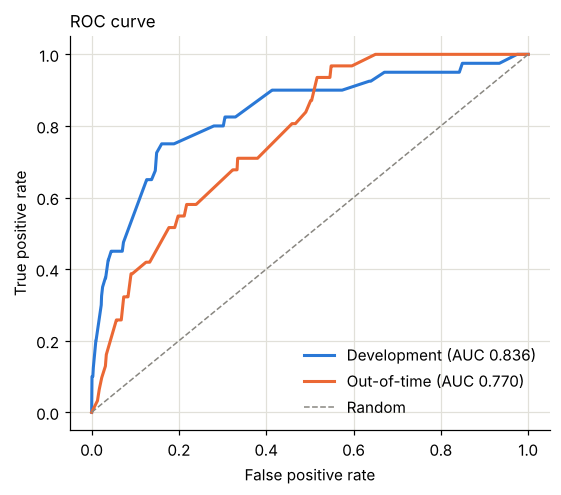

In [10]:
fig, ax = plt.subplots(figsize=(5.2, 4.6))
for d, lab, c in [(dev, "Development", BLUE), (oot, "Out-of-time", ORANGE)]:
    fpr, tpr, _ = roc_curve(d.default_12m, d.pd)
    ax.plot(fpr, tpr, color=c, lw=2, label=f"{lab} (AUC {roc_auc_score(d.default_12m, d.pd):.3f})")
ax.plot([0, 1], [0, 1], color=GREY, lw=1, ls="--", label="Random")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.set_title("ROC curve", loc="left", fontsize=11)
ax.legend(frameon=False, loc="lower right"); plt.tight_layout(); plt.savefig(FIG + "roc_curve.png"); plt.show()

**Calibration.** Rank ordering (AUC) is not enough; predicted PDs should also match observed default rates. With so few defaults, the OOT sample is split into quintiles rather than deciles.

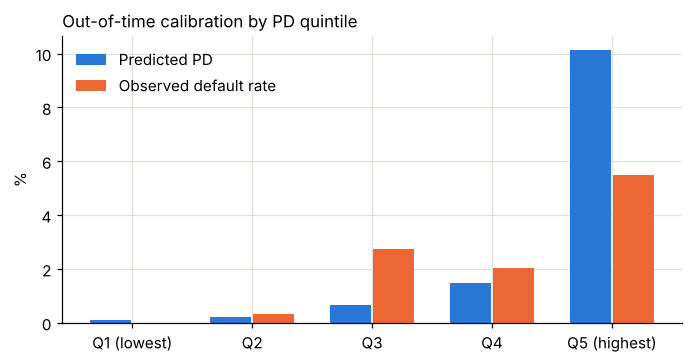

,obs,defaults,mean_pd,observed
quintile,,,,
Q1 (lowest),292,0,0.0012,0.0000
Q2,292,1,0.0023,0.0034
Q3,292,8,0.0067,0.0274
Q4,292,6,0.0146,0.0205
Q5 (highest),292,16,0.1013,0.0548


In [11]:
oot["quintile"] = pd.qcut(oot["pd"].rank(method="first"), 5, labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"])
cal = oot.groupby("quintile", observed=True).agg(obs=("pd", "size"), defaults=("default_12m", "sum"), mean_pd=("pd", "mean"), observed=("default_12m", "mean"))
fig, ax = plt.subplots(figsize=(6.4, 3.4)); x = np.arange(len(cal))
ax.bar(x - 0.18, cal.mean_pd * 100, 0.34, color=BLUE, label="Predicted PD")
ax.bar(x + 0.18, cal.observed * 100, 0.34, color=ORANGE, label="Observed default rate")
ax.set_xticks(x); ax.set_xticklabels(cal.index); ax.set_ylabel("%"); ax.legend(frameon=False)
ax.set_title("Out-of-time calibration by PD quintile", loc="left", fontsize=11); plt.tight_layout(); plt.savefig(FIG + "calibration.png"); plt.show()
cal

## 6. Scorecard and master scale

In [12]:
# Points scaling: 600 points = 50:1 good:bad odds, 20 points to double the odds (PDO)
PDO, BASE, BASE_ODDS = 20, 600, 50
factor = PDO / np.log(2); offset = BASE - factor * np.log(BASE_ODDS)
n = len(selected)
rows = []
for v in selected:
    b = model.params["woe_" + v]
    items = list(WOE[v]["woe"].items()) + ([(f"N/A (not {SECTOR_VARS[v]})", 0.0)] if v in SECTOR_VARS else [])
    for bin_, w in items:
        pts = -(w * b + model.params["const"] / n) * factor + offset / n
        rows.append({"variable": v, "bin": bin_, "woe": w, "points": round(pts)})
scorecard = pd.DataFrame(rows)
scorecard

,variable,bin,woe,points
0,dscr,"[-inf, 1.15)",1.9072,154
1,dscr,"[1.15, 1.3)",0.6535,186
2,dscr,"[1.3, 1.5)",0.3800,193
3,dscr,"[1.5, 1.85)",-0.7748,223
4,dscr,"[1.85, inf)",-1.2482,235
5,ltv,"[-inf, 0.55)",-0.7719,223
6,ltv,"[0.55, 0.65)",-0.7471,222
7,ltv,"[0.65, 0.75)",0.3625,194
8,ltv,"[0.75, inf)",1.9519,153
9,ltv,N/A (not CRE),0.0000,203


In [13]:
MASTER = pd.DataFrame({"grade": range(1, 10), "label": ["Exceptional", "Strong", "Good", "Satisfactory", "Acceptable", "Watch", "Special Mention", "Substandard", "Doubtful"],
                       "pd_upper": [0.002, 0.005, 0.01, 0.02, 0.04, 0.08, 0.18, 0.40, 1.0]})
def to_grade(p): return np.searchsorted(MASTER.pd_upper.values, p, side="right") + 1
def to_score(p): return np.round(offset + factor * np.log((1 - p) / p))
for d in (dev, oot):
    d["model_grade"] = np.minimum(to_grade(d.pd), 9); d["score"] = to_score(d.pd)
mg = oot.groupby("model_grade").agg(borrowers=("pd", "size"), defaults=("default_12m", "sum"), mean_pd=("pd", "mean"), observed=("default_12m", "mean"))
mg.join(MASTER.set_index("grade")[["label", "pd_upper"]])

,borrowers,defaults,mean_pd,observed,label,pd_upper
model_grade,,,,,,
1,434,0,0.0014,0.0000,Exceptional,0.0020
2,252,2,0.0032,0.0079,Strong,0.0050
3,223,7,0.0084,0.0314,Good,0.0100
4,231,5,0.0140,0.0216,Satisfactory,0.0200
5,117,4,0.0341,0.0342,Acceptable,0.0400
6,108,5,0.0539,0.0463,Watch,0.0800
7,68,6,0.1451,0.0882,Special Mention,0.1800
8,7,1,0.2172,0.1429,Substandard,0.4000
9,20,1,0.4566,0.0500,Doubtful,1.0000


## 7. Benchmark: model vs. the bank's current grades

The bank's grades are assigned by credit officers. Comparing the model against them on the same out-of-time borrowers shows whether the model adds information. The bank grade used is the worst grade on the borrower's loans at December 31, 2024, the same point in time as the model's inputs.

In [14]:
bank = pd.read_sql('''SELECT l.borrower_id, MAX(s.risk_grade) AS bank_grade FROM quarterly_snapshots s JOIN loans l ON l.loan_id = s.loan_id
                      WHERE s.as_of_date = '2024-12-31' GROUP BY l.borrower_id''', con)
cmp_ = oot.merge(bank, on="borrower_id", how="inner")
bench = pd.DataFrame({"AUC": {"Bank judgmental grade": roc_auc_score(cmp_.default_12m, cmp_.bank_grade),
                              "PD model": roc_auc_score(cmp_.default_12m, cmp_.pd),
                              "Model + bank grade (average rank)": roc_auc_score(cmp_.default_12m, cmp_.pd.rank() + cmp_.bank_grade.rank())},
                      "borrowers": len(cmp_)})
bench["Gini"] = 2 * bench["AUC"] - 1
bench

,AUC,borrowers,Gini
Bank judgmental grade,0.7130,1362,0.4259
PD model,0.7661,1362,0.5323
Model + bank grade (average rank),0.7696,1362,0.5393


In [15]:
pd.crosstab(cmp_.bank_grade, cmp_.model_grade, rownames=["Bank grade"], colnames=["Model grade"])

Model grade,1,2,3,4,5,6,7,8,9
Bank grade,,,,,,,,,
1,47,7,5,0,0,0,0,0,0
2,133,32,37,12,0,2,0,0,0
3,108,57,48,35,9,5,2,0,0
4,79,75,61,57,29,9,8,1,0
5,26,40,35,59,41,43,17,2,3
6,8,17,17,38,21,23,16,3,7
7,1,6,2,13,10,22,22,1,10
8,0,0,0,0,0,0,1,0,0


**Reading the benchmark.** On these out-of-time borrowers the model rank-orders risk better than the officers' grades (AUC about 0.77 vs 0.71), and blending the two adds a little more. Officers still see things the statements don't (management changes, lost customers, site visits), so the right use is as a **challenger and early-warning tool**: it is consistent, it updates the moment new statements arrive, and it flags borrowers whose grade may be stale.

In the crosstab, grades within one notch of each other are agreement; large gaps are where an analyst should look first, since either the model is missing qualitative information or the grade is stale.

## 8. Score the current portfolio and estimate expected loss

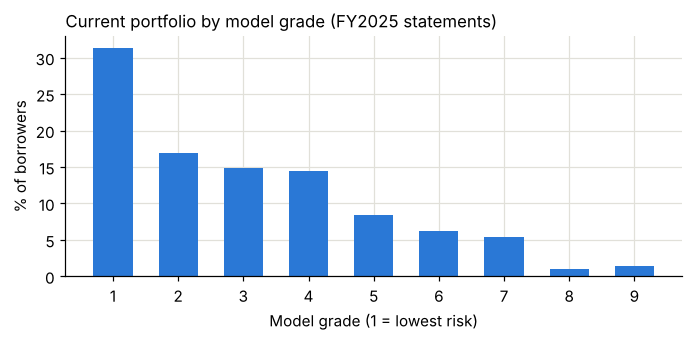

,borrowers,mean_pd,share
model_grade,,,
1,448,0.0014,0.3135
2,241,0.0032,0.1686
3,213,0.0084,0.1491
4,207,0.0137,0.1449
5,120,0.0348,0.0840
6,89,0.0543,0.0623
7,76,0.1473,0.0532
8,14,0.2172,0.0098
9,21,0.4566,0.0147


In [16]:
cur = df[df["sample"] == "Scoring"].copy()
cur["pd"] = predict(cur); cur["model_grade"] = np.minimum(to_grade(cur.pd), 9); cur["score"] = to_score(cur.pd)
con.execute("DROP TABLE IF EXISTS pd_scores")
cur[["borrower_id", "fiscal_year", "pd", "score", "model_grade"]].to_sql("pd_scores", con, index=False)
con.commit()
dist = cur.groupby("model_grade").agg(borrowers=("pd", "size"), mean_pd=("pd", "mean"))
dist["share"] = dist.borrowers / dist.borrowers.sum()
fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.bar(dist.index.astype(str), dist.share * 100, color=BLUE, width=0.6)
ax.set_xlabel("Model grade (1 = lowest risk)"); ax.set_ylabel("% of borrowers"); ax.set_title("Current portfolio by model grade (FY2025 statements)", loc="left", fontsize=11)
plt.tight_layout(); plt.savefig(FIG + "current_grade_distribution.png"); plt.show()
dist

In [17]:
el = pd.read_sql(open("../sql/13_expected_loss.sql").read(), con)
el

,industry,ead_mm,wtd_pd_pct,el_rate_pct,expected_loss_k
0,TOTAL,"2,444.4000",3.1700,0.9030,"22,066.0000"
1,CRE - Office,229.8000,16.8900,4.4360,"10,196.0000"
2,CRE - Hospitality,93.0000,8.2600,2.1690,"2,017.0000"
3,CRE - Senior Housing,129.1000,5.7300,1.5060,"1,945.0000"
4,CRE - Multifamily,541.9000,1.1400,0.2990,"1,620.0000"
5,Construction,81.7000,3.1100,1.3300,"1,086.0000"
6,CRE - Retail,215.4000,1.8400,0.4840,"1,043.0000"
7,Transportation,64.1000,3.3300,1.4280,916.0000
8,Restaurants,47.4000,3.6400,1.5150,717.0000
9,Energy Services,52.6000,2.6500,1.1770,620.0000


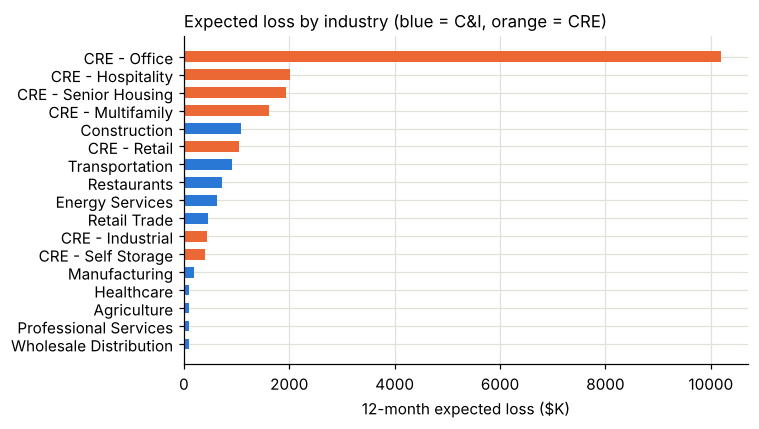

In [18]:
fig, ax = plt.subplots(figsize=(7, 4))
e = el[el.industry != "TOTAL"].sort_values("expected_loss_k")
colors = [ORANGE if i.startswith("CRE") else BLUE for i in e.industry]
ax.barh(e.industry, e.expected_loss_k, color=colors, height=0.6)
ax.set_xlabel("12-month expected loss ($K)"); ax.set_title("Expected loss by industry (blue = C&I, orange = CRE)", loc="left", fontsize=11)
plt.tight_layout(); plt.savefig(FIG + "expected_loss_by_industry.png"); plt.show()

### Early read on 2026

Outcomes for FY2025 scores are only observed through September 30, 2026, so this is an early check, not a validation.

In [19]:
early = cur.groupby(pd.cut(cur.model_grade, [0, 3, 5, 6, 9], labels=["Grades 1-3", "Grades 4-5", "Grade 6", "Grades 7-9"]), observed=True).agg(
    borrowers=("pd", "size"), defaults_through_sep_2026=("default_12m", "sum"), mean_pd=("pd", "mean"))
early

,borrowers,defaults_through_sep_2026,mean_pd
model_grade,,,
Grades 1-3,902,9,0.0035
Grades 4-5,327,5,0.0215
Grade 6,89,4,0.0543
Grades 7-9,111,16,0.2147


## 9. Conclusions and limitations

**What the model does well**
- Rank-orders default risk on a later period it never saw (OOT AUC about 0.77 vs 0.84 in development), a normal amount of decay for a small sample.
- Outperforms the bank's judgmental grades on the same borrowers using three financial and industry variables.
- Every variable is explainable to a credit officer: debt service coverage, loan-to-value for real estate, and industry risk.
- Produces a PD, a score, and a grade on the bank's existing scale, so it slots into current reporting.

**Limitations**
- PDs are too spread out: the riskiest quintile is overpredicted and the middle is underpredicted on the OOT sample. The PD scale should be recalibrated before use in loss estimates.
- C&I leverage and liquidity showed no added signal beyond DSCR in this sample; with more defaults they may earn a place.
- Small number of defaults (a typical problem for commercial portfolios), so estimates carry wide confidence intervals.
- One economic environment in the data; PDs are point-in-time and should be adjusted toward a through-the-cycle view before use in capital or CECL.
- Synthetic data: the model recovers relationships that were built into the simulation.

**Next steps**
- Add qualitative factors (management, financial reporting quality) the way most commercial scorecards do.
- Calibrate to a long-run central tendency and set up monitoring: population stability index, quarterly AUC, and grade-level default rate tests.